In [1]:
from pathlib import Path
from typing import cast

import copy
import json
import time

# pytorch
import torch
from torch import nn
from torch_geometric.data import Data

from dataset import add_stratified_masks, load_facebook_data
from modules import GCNNetwork
from train import evaluate_gcn, train_gcn_epoch

# plotting
from matplotlib import pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### GCN Experiments
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Config and Constants

In [2]:
# constants
SEED = 808

# data parameters
TRAIN_PCT = 60
VAL_PCT = 20
TEST_PCT = 20

# GCN model parameters
HIDDEN_CHANNELS = 64
DROPOUT = 0.5

# hyper-parameters
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0
EPOCHS = 4000

# plot styling
sns.set_theme(
    context="notebook",
    style="whitegrid",
)

# output paths
RESULTS_DIR = Path("results")
CHECKPOINTS_DIR = Path("checkpoints")
FIGURES_DIR = Path("images/gcn")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


Load the Facebook Graph

In [4]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()
data = dataset[0]  # get first graph object

# create reproducible stratified train/validation/test splits
add_stratified_masks(
    cast(Data, data),
    train_pct=TRAIN_PCT,
    val_pct=VAL_PCT,
    test_pct=TEST_PCT,
    seed=SEED,
)

# load data onto the device
data = data.to(device)

Instantiate the GCN network

In [5]:
gcn_model = GCNNetwork(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser

In [6]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform Initial GCN Experiment for comparison with MLP Baseline

In [7]:
# perform training and validation of the Initial GCN

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
best_epoch = 0
best_state = None

print("> Training GCN")

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_gcn_epoch(
        model=gcn_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(
            gcn_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:3}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

elapsed = time.perf_counter() - start

print(
    f"\nTraining took {elapsed:.2f} secs "
    f"or {elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {best_val_loss:.5f} "
    f"at epoch {best_epoch}."
)

> Training GCN
Epoch [  1/4000] Train Loss: 1.37681 | Val Loss: 1.36711 | Val Acc: 30.84% *
Epoch [  2/4000] Train Loss: 1.36890 | Val Loss: 1.35985 | Val Acc: 33.13% *
Epoch [  3/4000] Train Loss: 1.36362 | Val Loss: 1.35271 | Val Acc: 33.80% *
Epoch [  4/4000] Train Loss: 1.35580 | Val Loss: 1.34568 | Val Acc: 34.60% *
Epoch [  5/4000] Train Loss: 1.35000 | Val Loss: 1.33874 | Val Acc: 35.29% *
Epoch [  6/4000] Train Loss: 1.34083 | Val Loss: 1.33189 | Val Acc: 35.96% *
Epoch [  7/4000] Train Loss: 1.33244 | Val Loss: 1.32514 | Val Acc: 36.67% *
Epoch [  8/4000] Train Loss: 1.32851 | Val Loss: 1.31846 | Val Acc: 37.21% *
Epoch [  9/4000] Train Loss: 1.32288 | Val Loss: 1.31186 | Val Acc: 37.67% *
Epoch [ 10/4000] Train Loss: 1.31182 | Val Loss: 1.30533 | Val Acc: 37.98% *
Epoch [ 11/4000] Train Loss: 1.30764 | Val Loss: 1.29885 | Val Acc: 38.70% *
Epoch [ 12/4000] Train Loss: 1.30263 | Val Loss: 1.29244 | Val Acc: 39.45% *
Epoch [ 13/4000] Train Loss: 1.29387 | Val Loss: 1.28606 | Va

In [8]:
# save initial GCN experiment results

if best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn_results = {
    "model": "GCN",
    "experiment": "initial",
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "selected_val_accuracy": history[
        "val_accuracy"
    ][best_epoch - 1],
    "training_seconds": elapsed,
    "device": str(device),
    "history": history,
}

with (
    RESULTS_DIR / "gcn_initial.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn_results,
        file,
        indent=2,
    )

torch.save(
    best_state,
    CHECKPOINTS_DIR / "gcn_initial.pt",
)

Visualise the Train/Val metrics

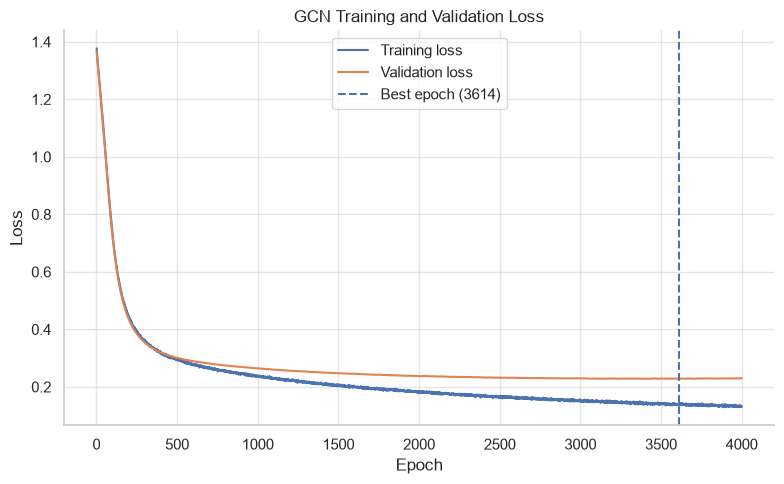

In [9]:
# plot the training and validation losses

gcn_epochs = range(
    1,
    len(history["train_loss"]) + 1
)

gcn_loss_fig, gcn_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn_loss_ax.plot(
    gcn_epochs,
    history["train_loss"],
    label="Training loss",
)
gcn_loss_ax.plot(
    gcn_epochs,
    history["val_loss"],
    label="Validation loss",
)
gcn_loss_ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})",
)

gcn_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="GCN Training and Validation Loss",
)
gcn_loss_ax.legend()

sns.despine(ax=gcn_loss_ax)
gcn_loss_fig.tight_layout()

plt.show()

In [10]:
# save the initial gcn validation loss plot
gcn_loss_fig.savefig(
    FIGURES_DIR / "gcn_training_validation_loss_initial_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics

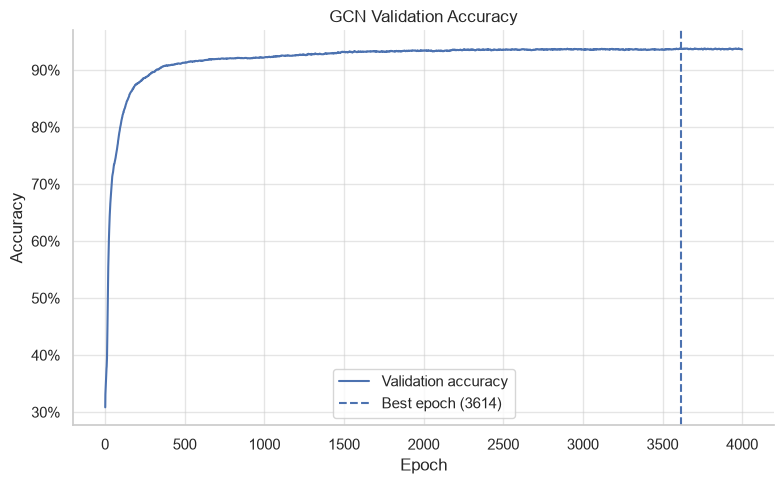

In [11]:
# plot GCN validation accuracy

gcn_accuracy_fig, gcn_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn_accuracy_ax.plot(
    gcn_epochs,
    history["val_accuracy"],
    label="Validation accuracy",
)
gcn_accuracy_ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})",
)

gcn_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="GCN Validation Accuracy",
)
gcn_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn_accuracy_ax.legend()

sns.despine(ax=gcn_accuracy_ax)
gcn_accuracy_fig.tight_layout()

plt.show()

In [12]:
# save the initial gcn validation acc plot
gcn_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_training_validation_acc_initial_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Evaluate the Initial GCN model performance

In [ ]:
# evaluate the initial GCN model on the held-out test set
# NOTE: final held-out GCN test evaluation - run only after model selection is complete

if best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn_model.load_state_dict(best_state)

print(f"Restored model from epoch {best_epoch}.")

test_loss, test_accuracy = evaluate_gcn(
    model=gcn_model,
    features=data.x,
    edge_index=data.edge_index,
    labels=data.y,
    mask=data.test_mask,
    criterion=criterion,
)

print(
    f"Test Loss: {test_loss:.5f} | "
    f"Test Accuracy: {test_accuracy:.2%}"
)